In [2]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

In [3]:
import pandas as pd
data = {
    "Employee": [
        "Rajiv",
        "Amit",
        "Priya",
        "Rahul",
        "Sneha",
        "Vikash"
    ],
    "Department": [
        "IT",
        "HR",
        "IT",
        "Finance",
        "IT",
        "Finance"
    ],
    "Salary": [
        90000,
        70000,
        120000,
        85000,
        110000,
        95000
    ],
    "Experience": [
        8,
        5,
        10,
        7,
        6,
        9
    ],
    "Location": [
        "Bangalore",
        "Mumbai",
        "Bangalore",
        "Delhi",
        "Chennai",
        "Chennai"
    ]
}

In [4]:
df = pd.DataFrame(data)
df.to_excel("employees.xlsx", index=False)

print("Excel file created successfully!")

Excel file created successfully!


In [6]:
df = pd.read_excel("employees.xlsx")
df

,Employee,Department,Salary,Experience,Location
0,Rajiv,IT,90000,8,Bangalore
1,Amit,HR,70000,5,Mumbai
2,Priya,IT,120000,10,Bangalore
3,Rahul,Finance,85000,7,Delhi
4,Sneha,IT,110000,6,Chennai
5,Vikash,Finance,95000,9,Chennai


In [7]:
import sqlite3

In [8]:
connection = sqlite3.connect("employees.db")

In [10]:
df.to_sql(
    "employees",
    connection,
    if_exists="replace",
    index=False
)

print("Excel data loaded into SQLite!")

Excel data loaded into SQLite!


In [12]:
# Install and import cmic database into our sqlite
!sqlite3 employees.db ".read ./employee_create_script.sql"

In [13]:
# Running query on DB which will return all the tables from our sqlite DB
!sqlite3 employees.db "SELECT name FROM sqlite_master WHERE type='table';"

employees


In [14]:
## LangChain provided utility to connect a databse and execute query
from langchain_community.utilities import SQLDatabase

db = SQLDatabase.from_uri("sqlite:///employees.db")
db

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_97944/1953295336.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


In [15]:
print(db.dialect)
print(db.get_usable_table_names())

sqlite
['employees']


In [16]:
db.run("SELECT * FROM employees LIMIT 10;", include_columns=True)

"[{'Employee': 'Rajiv', 'Department': 'IT', 'Salary': 90000, 'Experience': 8, 'Location': 'Bangalore'}, {'Employee': 'Amit', 'Department': 'HR', 'Salary': 70000, 'Experience': 5, 'Location': 'Mumbai'}, {'Employee': 'Priya', 'Department': 'IT', 'Salary': 120000, 'Experience': 10, 'Location': 'Bangalore'}, {'Employee': 'Rahul', 'Department': 'Finance', 'Salary': 85000, 'Experience': 7, 'Location': 'Delhi'}, {'Employee': 'Sneha', 'Department': 'IT', 'Salary': 110000, 'Experience': 6, 'Location': 'Chennai'}, {'Employee': 'Vikash', 'Department': 'Finance', 'Salary': 95000, 'Experience': 9, 'Location': 'Chennai'}]"

In [17]:
# This command will return the schema of a given table
print(db.get_table_info(table_names=['employees']))


CREATE TABLE employees (
	"Employee" TEXT, 
	"Department" TEXT, 
	"Salary" INTEGER, 
	"Experience" INTEGER, 
	"Location" TEXT
)

/*
3 rows from employees table:
Employee	Department	Salary	Experience	Location
Rajiv	IT	90000	8	Bangalore
Amit	HR	70000	5	Mumbai
Priya	IT	120000	10	Bangalore
*/


In [20]:
# from langchain_core.prompts.prompt import PromptTemplate

# # table_info will be retrieved by databse engine and will have schema about tables all the tabled in our sqlite database.
# # input will be replaced by the user query.
# PROMPT_SUFFIX = """Only use the following tables:
# {table_info}

# User question:{question}"""

# _sqlite_prompt = """
# You are an expert SQLite SQL developer.

# Database table:

# employees

# Columns:

# Employee TEXT
# Department TEXT
# Salary INTEGER
# Experience INTEGER
# Location TEXT

# Convert the user's question into a SQLite SELECT query.

# Rules:
# - Only generate SELECT queries.
# - Do not use INSERT, UPDATE, DELETE, DROP, ALTER, or CREATE.
# - Use only the employees table.
# - Return only SQL.
# - Do not use markdown.
# """
from langchain_core.messages import SystemMessage

SQL_PREFIX = """You are an agent designed to interact with a SQL database in SQLite.
Given an input question, create a syntactically correct SQLite query to run, then look at the results of the query and return the answer.
Unless the user specifies a specific number of examples they wish to obtain, always limit your query to at most 3 results.
You can order the results by a relevant column to return the most interesting examples in the database.
Never query for all the columns from a specific table, only ask for the relevant columns given the question.
Make sure you generate a correct SQLite query as plain text without any formatting or code blocks.
Do not include sql or similar markers.
Do not try to explain the query, just provide the query as-is, like this: SELECT ...

You have access to tools for interacting with the database.
Only use the below tools. Only use the information returned by the below tools to construct your final answer.

You MUST double check your query before executing it. If you get an error while executing a query, rewrite the query and try again.
DO NOT make any DML statements (INSERT, UPDATE, DELETE, DROP etc.) to the database even if the user asks.

To start you should ALWAYS look at the tables in the database to see what you can query.
Do NOT skip this step.
Then you should query the schema of the most relevant tables.

When generating the final answer in markdown from the results,
if there are special characters in the text, such as the dollar symbol,
ensure they are escaped properly for correct rendering e.g $25.5 should become \$25.5
"""

SYS_PROMPT = SystemMessage(content=SQL_PREFIX)

<>:57: SyntaxWarning: invalid escape sequence '\$'
<>:57: SyntaxWarning: invalid escape sequence '\$'
/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_97944/3736092735.py:57: SyntaxWarning: invalid escape sequence '\$'
  ensure they are escaped properly for correct rendering e.g $25.5 should become \$25.5


In [19]:
# DB_QUERY, DB_SCHEMA,DB_LIST_TABLES and DB_QUERY_CHECKER are available under LangChain "SQLDatabaseToolkit"

from langchain_community.agent_toolkits import SQLDatabaseToolkit

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o", temperature=0)

sql_toolkit = SQLDatabaseToolkit(db=db, llm=llm)

sql_tools = sql_toolkit.get_tools()

# You can see it has 4 tools
sql_tools

[QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x138ba7770>),
 InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x138ba7770>),
 ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x138ba7770>),
 QuerySQLCheckerTool(description='Use this tool to double check if your 

In [21]:
from langchain_core.messages import HumanMessage

from langgraph.prebuilt import create_react_agent

from langchain_openai import ChatOpenAI

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_97944/2090458912.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  text2sql_agent = create_react_agent(model=llm,


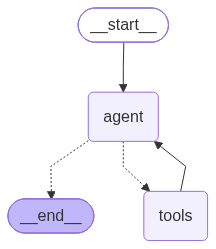

In [22]:
text2sql_agent = create_react_agent(model=llm,
                                    tools=sql_tools,
                                    prompt=SYS_PROMPT)
text2sql_agent

In [23]:
from IPython.display import display, Markdown

In [24]:
for event in text2sql_agent.stream(
    {"messages": [HumanMessage(content="Show IT employees with more than 7 years of experience?")]},
    stream_mode='values' #returns full agent state with all messages including updates
):
    event["messages"][-1].pretty_print()

print('\n\nFinal Response:\n')
display(Markdown(event["messages"][-1].content))

================================ Human Message =================================

Show IT employees with more than 7 years of experience?
================================== Ai Message ==================================
Tool Calls:
  sql_db_list_tables (call_kMfmFwL9qsPh3TUk8xJxumDA)
 Call ID: call_kMfmFwL9qsPh3TUk8xJxumDA
  Args:
================================= Tool Message =================================
Name: sql_db_list_tables

employees
================================== Ai Message ==================================
Tool Calls:
  sql_db_schema (call_lPbHDOMFDHknG21eQB0rokwl)
 Call ID: call_lPbHDOMFDHknG21eQB0rokwl
  Args:
    table_names: employees
================================= Tool Message =================================
Name: sql_db_schema


CREATE TABLE employees (
	"Employee" TEXT, 
	"Department" TEXT, 
	"Salary" INTEGER, 
	"Experience" INTEGER, 
	"Location" TEXT
)

/*
3 rows from employees table:
Employee	Department	Salary	Experience	Location
Rajiv	IT	90000	8	Bangalo

Here are IT employees with more than 7 years of experience:

1. Rajiv - 8 years
2. Priya - 10 years

In [25]:
def call_text2sql_agent(query, verbose=False):
    
    for event in text2sql_agent.stream(
        {"messages": [HumanMessage(content=query)]},
        stream_mode='values' #returns full agent state with all messages including updates
    ):
        if verbose:
            event["messages"][-1].pretty_print()

    print('\n\nFinal Response:\n')
    display(Markdown(event["messages"][-1].content))

In [26]:
call_text2sql_agent(query="Show all employees from Chennai",
                    verbose=True)

================================ Human Message =================================

Show all employees from Chennai
================================== Ai Message ==================================
Tool Calls:
  sql_db_list_tables (call_HUZ9mXF1dQd9vnfUHaEwP4On)
 Call ID: call_HUZ9mXF1dQd9vnfUHaEwP4On
  Args:
================================= Tool Message =================================
Name: sql_db_list_tables

employees
================================== Ai Message ==================================
Tool Calls:
  sql_db_schema (call_RniAMKaAjsF59CwgVVRoEWUk)
 Call ID: call_RniAMKaAjsF59CwgVVRoEWUk
  Args:
    table_names: employees
================================= Tool Message =================================
Name: sql_db_schema


CREATE TABLE employees (
	"Employee" TEXT, 
	"Department" TEXT, 
	"Salary" INTEGER, 
	"Experience" INTEGER, 
	"Location" TEXT
)

/*
3 rows from employees table:
Employee	Department	Salary	Experience	Location
Rajiv	IT	90000	8	Bangalore
Amit	HR	70000	5	Mumba

Here are the employees from Chennai:

1. **Sneha**
   - Department: IT
   - Salary: \$110,000
   - Experience: 6 years

2. **Vikash**
   - Department: Finance
   - Salary: \$95,000
   - Experience: 9 years

In [27]:
call_text2sql_agent(query="give me the details of the employees whose name is Rajiv",
                    verbose=True)

================================ Human Message =================================

give me the details of the employees whose name is Rajiv
================================== Ai Message ==================================
Tool Calls:
  sql_db_list_tables (call_vrvKxlgqaXqDiGXCM9UQzYLH)
 Call ID: call_vrvKxlgqaXqDiGXCM9UQzYLH
  Args:
================================= Tool Message =================================
Name: sql_db_list_tables

employees
================================== Ai Message ==================================
Tool Calls:
  sql_db_schema (call_HQQYchikhOLapziEDrLAHjlb)
 Call ID: call_HQQYchikhOLapziEDrLAHjlb
  Args:
    table_names: employees
================================= Tool Message =================================
Name: sql_db_schema


CREATE TABLE employees (
	"Employee" TEXT, 
	"Department" TEXT, 
	"Salary" INTEGER, 
	"Experience" INTEGER, 
	"Location" TEXT
)

/*
3 rows from employees table:
Employee	Department	Salary	Experience	Location
Rajiv	IT	90000	8	Bangal

The details of the employee named Rajiv are as follows:

- **Employee Name:** Rajiv
- **Department:** IT
- **Salary:** \$90,000
- **Experience:** 8 years
- **Location:** Bangalore